# DSCI 552 – Homework 6

**Name:** Pooja Nandyappa Subashchandra  
**GitHub Username:** nandyapp-afk  
**USC ID:** 1768721225

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, auc, confusion_matrix, roc_curve
from sklearn.model_selection import StratifiedKFold
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=FutureWarning)

# Relative paths (forward slashes only)
TRAIN_PATH = "data/APSFailure/aps_failure_training_set.csv"
TEST_PATH = "data/APSFailure/aps_failure_test_set.csv"

SEED = 0
N_TREES = 100                       # trees in the random forests
ALPHAS = [0, 0.1, 1, 10, 100]       # grid for the L1 regularization term of XGBoost

## Problem 1 – Tree-Based Methods

### 1(a) Load the APS Failure data

The files start with a license header, so the lines before the column names are skipped. Missing values are coded as `na`, and the class is `neg` / `pos` (coded 0 / 1).

In [2]:
def read_aps(path):
    with open(path) as f:
        skip = next(i for i, line in enumerate(f) if line.startswith("class,"))
    df = pd.read_csv(path, skiprows=skip, na_values="na")
    y = (df.pop("class") == "pos").astype(int).to_numpy()
    return df, y


X_train, y_train = read_aps(TRAIN_PATH)
X_test, y_test = read_aps(TEST_PATH)

### 1(b)i Missing values

Common techniques for data with missing values (data imputation) are: deleting the rows (or the columns) with missing values; replacing the missing values of a feature by its mean, median or mode; adding a missing-value indicator; and model-based imputation such as k-nearest-neighbours, regression or iterative (MICE) imputation. Deleting rows is not a good option when many rows contain missing values, since a large part of the data, including the scarce positive class, would be lost.

**Median imputation** is applied: it is simple, scales to 60,000 × 170 values, and is robust to the strong skewness of these features. Following footnote 1, each set is imputed with its own medians (the training set with the training medians and the test set with the test medians).

In [3]:
missing_before = (int(X_train.isna().sum().sum()), int(X_test.isna().sum().sum()))
X_train = X_train.fillna(X_train.median()).fillna(0)      # fillna(0): a column that is entirely missing
X_test = X_test.fillna(X_test.median()).fillna(0)
print(f"Missing values before imputation: training set {missing_before[0]}, test set {missing_before[1]}; "
      f"after: {int(X_train.isna().sum().sum() + X_test.isna().sum().sum())}")

Missing values before imputation: training set 850015, test set 228680; after: 0


### 1(b)ii Coefficient of variation of each feature

CV = s / m, with s the sample standard deviation and m the sample mean of the feature (training set, after imputation).

In [4]:
cv = (X_train.std() / X_train.mean()).replace([np.inf, -np.inf], np.nan)
pd.set_option("display.max_rows", 180)
cv.sort_values(ascending=False).rename("CV").to_frame()

,CV
cf_000,244.887517
co_000,244.507385
ad_000,244.322816
cs_009,237.930554
dh_000,123.216097
dj_000,117.494225
ag_000,92.917755
as_000,87.332500
ay_009,84.733735
ak_000,80.424975


### 1(b)iii Correlation matrix of the features

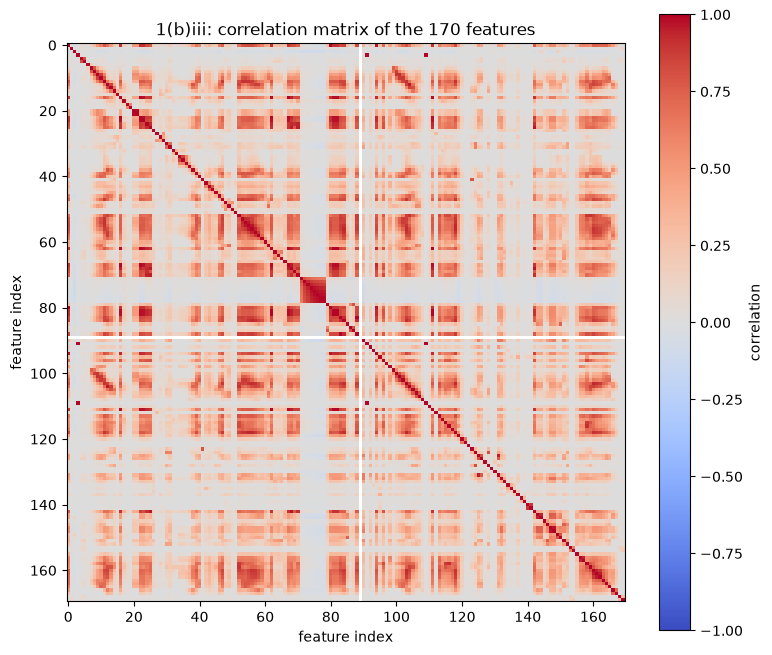

In [5]:
corr = X_train.corr()
plt.figure(figsize=(9, 8))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="correlation")
plt.xlabel("feature index")
plt.ylabel("feature index")
plt.title("1(b)iii: correlation matrix of the 170 features")
plt.show()

### 1(b)iv The ⌊√170⌋ = 13 features with the highest CV

Scatter plots of the features (red = positive class, blue = negative class; for readability all positive points and 5,000 randomly chosen negative points are drawn) and box plots of each feature for the two classes, similar to p. 129 of ISLR.

Features with the highest CV: ['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000']


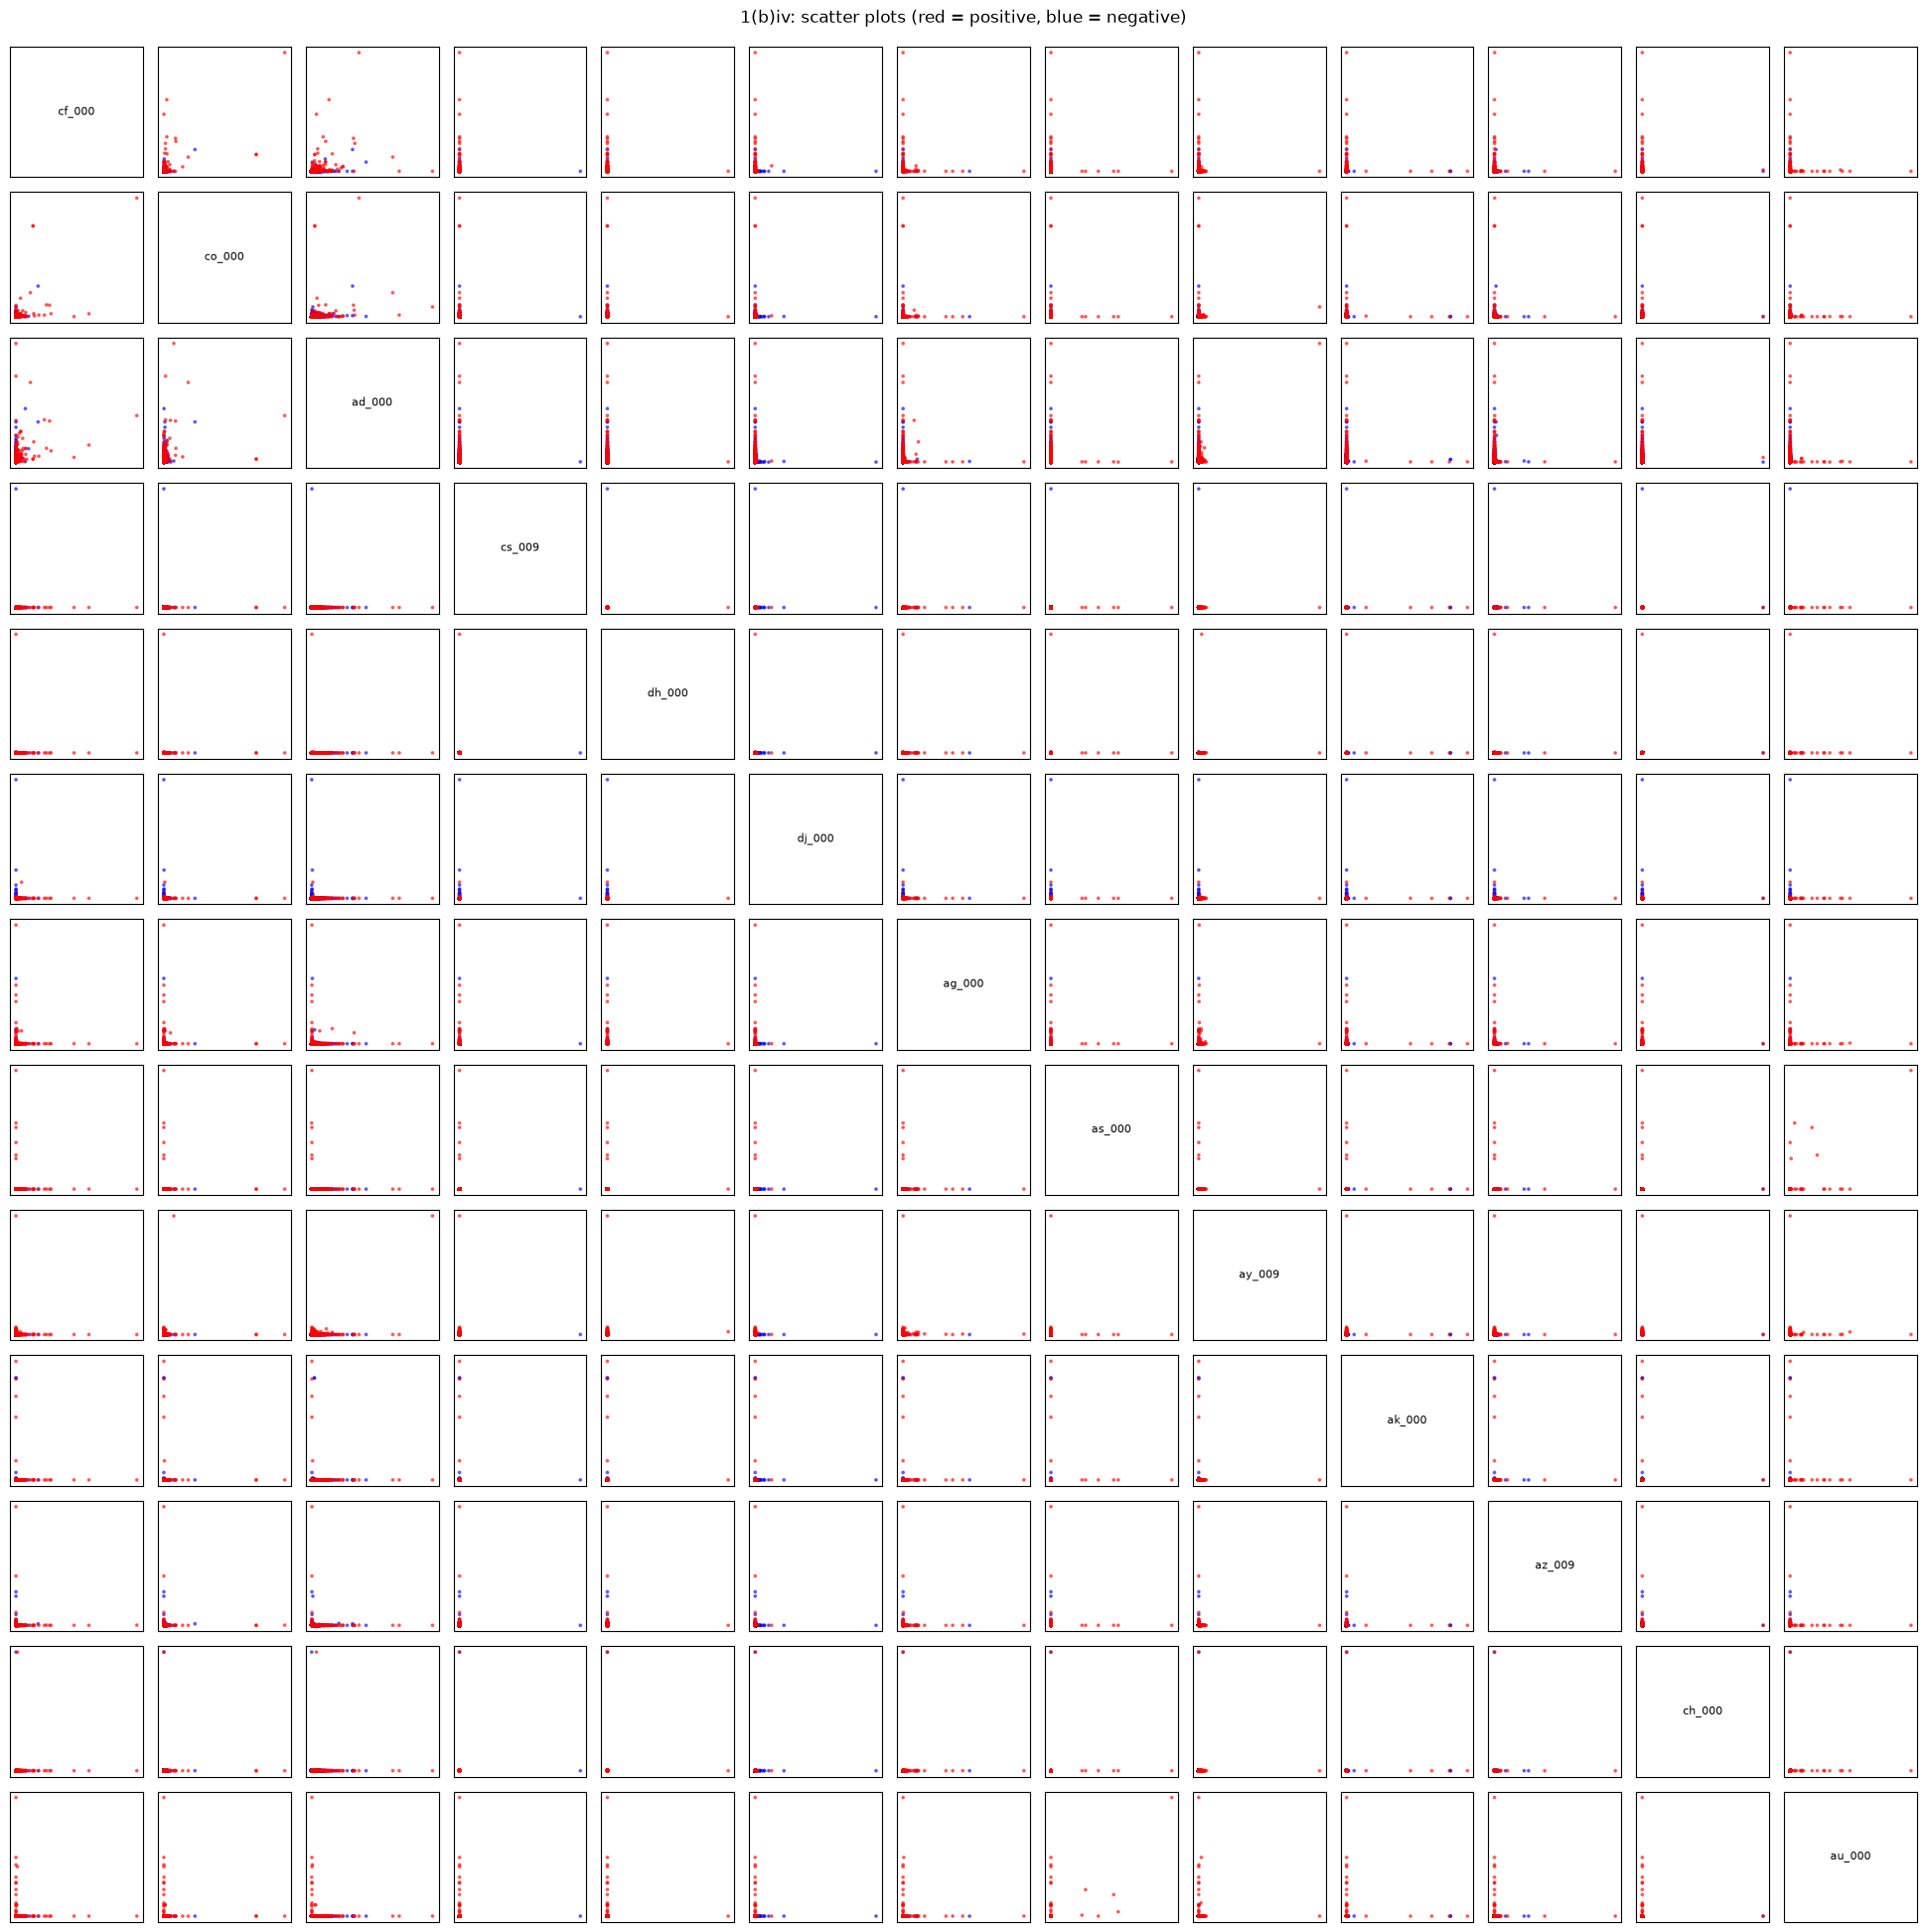

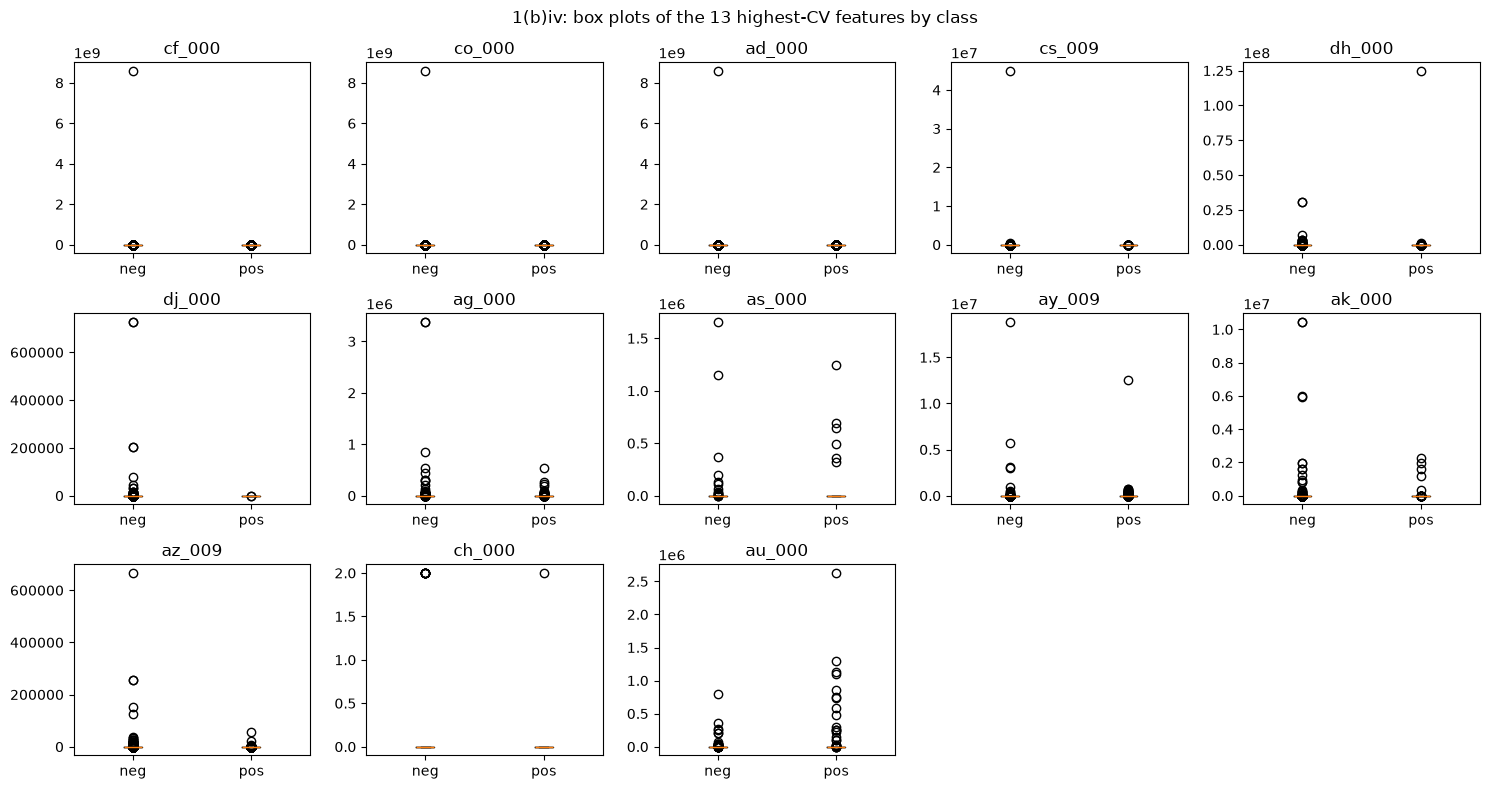

In [6]:
top = list(cv.nlargest(int(np.floor(np.sqrt(170)))).index)
print("Features with the highest CV:", top)

rng = np.random.default_rng(SEED)
neg = rng.choice(np.where(y_train == 0)[0], size=min(5000, int((y_train == 0).sum())), replace=False)
idx = np.r_[neg, np.where(y_train == 1)[0]]                  # positives are drawn last (on top)
X_plot, y_plot = X_train[top].to_numpy()[idx], y_train[idx]

k = len(top)
fig, axes = plt.subplots(k, k, figsize=(1.5 * k, 1.5 * k))
colors = np.where(y_plot == 1, "red", "blue")
for r in range(k):
    for c in range(k):
        ax = axes[r, c]
        if r == c:
            ax.text(0.5, 0.5, top[c], ha="center", va="center", fontsize=8)
        else:
            ax.scatter(X_plot[:, c], X_plot[:, r], c=colors, s=3, alpha=0.5)
        ax.set_xticks([])
        ax.set_yticks([])
fig.suptitle("1(b)iv: scatter plots (red = positive, blue = negative)", y=0.995)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(3, 5, figsize=(15, 8))
for ax, f in zip(axes.ravel(), top):
    ax.boxplot([X_train[f].to_numpy()[y_train == 0], X_train[f].to_numpy()[y_train == 1]])
    ax.set_xticks([1, 2])
    ax.set_xticklabels(["neg", "pos"])
    ax.set_title(f)
for ax in axes.ravel()[len(top):]:
    ax.axis("off")
fig.suptitle("1(b)iv: box plots of the 13 highest-CV features by class")
plt.tight_layout()
plt.show()

**Answer:** No. All 13 features are extremely right-skewed: almost all values are close to 0 for both classes, and a few extreme outliers stretch the axes, so the points of the two classes overlap and cannot be told apart. In addition, a scatter plot shows only the marginal behaviour of one feature and cannot establish statistical significance, which requires a hypothesis test or a model.

### 1(b)v Number of positive and negative instances

In [7]:
pd.DataFrame({"training set": np.bincount(y_train), "test set": np.bincount(y_test)},
             index=["negative", "positive"])

,training set,test set
negative,59000,15625
positive,1000,375


**Answer:** Yes, the data set is strongly imbalanced: the training set has 59,000 negative and only 1,000 positive instances (1.7% positive).

### 1(c) Random forest without compensation for class imbalance

Misclassification error is the fraction of misclassified instances (threshold 0.5 on the predicted probability). The out-of-bag (OOB) error estimate is 1 − OOB accuracy.

Random forest, training set: misclassification error = 0.0000, AUC = 1.0000


,pred neg,pred pos
true neg,59000,0
true pos,0,1000


Random forest, test set: misclassification error = 0.0074, AUC = 0.9944


,pred neg,pred pos
true neg,15609,16
true pos,102,273


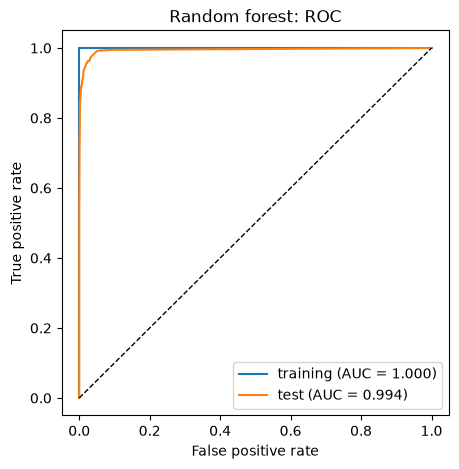

OOB error estimate = 0.0062   test error = 0.0074


In [8]:
Xtr, Xte = X_train.to_numpy(), X_test.to_numpy()


def report(model, name):
    """Confusion matrix, misclassification error, ROC and AUC on the training and the test set."""
    results = {}
    plt.figure(figsize=(5, 5))
    for label, X, y in [("training", Xtr, y_train), ("test", Xte, y_test)]:
        pred = model.predict(X)
        score = model.predict_proba(X)[:, 1]
        fpr, tpr, _ = roc_curve(y, score)
        results[label] = {"error": 1 - accuracy_score(y, pred), "auc": auc(fpr, tpr)}
        print(f"{name}, {label} set: misclassification error = {results[label]['error']:.4f}, "
              f"AUC = {results[label]['auc']:.4f}")
        display(pd.DataFrame(confusion_matrix(y, pred, labels=[0, 1]),
                             index=["true neg", "true pos"], columns=["pred neg", "pred pos"]))
        plt.plot(fpr, tpr, label=f"{label} (AUC = {results[label]['auc']:.3f})")
    plt.plot([0, 1], [0, 1], "k--", linewidth=1)
    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate")
    plt.title(f"{name}: ROC")
    plt.legend(loc="lower right")
    plt.show()
    return results


rf = RandomForestClassifier(n_estimators=N_TREES, oob_score=True, n_jobs=-1, random_state=SEED).fit(Xtr, y_train)
res_rf = report(rf, "Random forest")
oob_rf = 1 - rf.oob_score_
print(f"OOB error estimate = {oob_rf:.4f}   test error = {res_rf['test']['error']:.4f}")

**Answer:** The OOB error estimate (0.0062) is close to the test error (0.0074), slightly lower, so the OOB error is a good estimate of the test error. The training error of 0 is not informative about the test error.

### 1(d) Random forest with compensation for class imbalance

Common ways to address class imbalance in random forests are: cost-sensitive learning with class weights (in the split criterion and in the votes); balanced random forests, where every tree is grown on a balanced bootstrap sample (the majority class is down-sampled); resampling the training data (under-sampling, over-sampling, SMOTE) before fitting; and moving the classification threshold on the predicted class probability.

Here class weights are used: `class_weight="balanced_subsample"` weights each class inversely to its frequency in the bootstrap sample of each tree.

Random forest, balanced class weights, training set: misclassification error = 0.0000, AUC = 1.0000


,pred neg,pred pos
true neg,59000,0
true pos,0,1000


Random forest, balanced class weights, test set: misclassification error = 0.0104, AUC = 0.9895


,pred neg,pred pos
true neg,15611,14
true pos,153,222


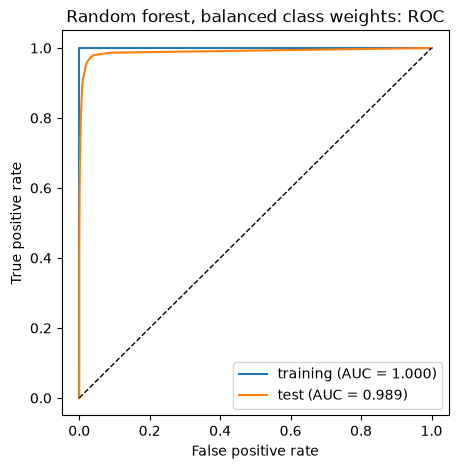

OOB error estimate = 0.0077   test error = 0.0104


,OOB error,training error,test error,training AUC,test AUC
1(c) no compensation,0.0062,0.0,0.0074,1.0,0.9944
1(d) balanced class weights,0.0077,0.0,0.0104,1.0,0.9895


In [9]:
rf_bal = RandomForestClassifier(n_estimators=N_TREES, oob_score=True, class_weight="balanced_subsample",
                                n_jobs=-1, random_state=SEED).fit(Xtr, y_train)
res_rf_bal = report(rf_bal, "Random forest, balanced class weights")
oob_rf_bal = 1 - rf_bal.oob_score_
print(f"OOB error estimate = {oob_rf_bal:.4f}   test error = {res_rf_bal['test']['error']:.4f}")

pd.DataFrame({
    "OOB error": [oob_rf, oob_rf_bal],
    "training error": [res_rf["training"]["error"], res_rf_bal["training"]["error"]],
    "test error": [res_rf["test"]["error"], res_rf_bal["test"]["error"]],
    "training AUC": [res_rf["training"]["auc"], res_rf_bal["training"]["auc"]],
    "test AUC": [res_rf["test"]["auc"], res_rf_bal["test"]["auc"]],
}, index=["1(c) no compensation", "1(d) balanced class weights"]).round(4)

**Answer:** Balanced class weights did not improve the results. The test error increased from 0.0074 to 0.0104, the number of missed positive instances increased from 102 to 153 (false positives: 16 against 14), and the test AUC decreased from 0.9944 to 0.9895. The OOB error also increased, from 0.0062 to 0.0077.

### 1(e) XGBoost with L1 regularization, without compensation for class imbalance

An XGBoost classifier (logistic loss) is fitted with the L1 regularization term `reg_alpha` (α) on the leaf weights. α is chosen by stratified 5-fold cross-validation over the grid {0, 0.1, 1, 10, 100}, using the misclassification error (1 − accuracy); ties are broken by the larger α. The other settings are fixed (100 trees, learning rate 0.1, maximum depth 3). The cross-validation error at the selected α is the estimate of the error of the model, to be compared with the test error.

,CV error
alpha,
0.0,0.00705
0.1,0.00688
1.0,0.00687
10.0,0.00765
100.0,0.01170


Selected alpha = 1   5-fold CV error = 0.0069
XGBoost, training set: misclassification error = 0.0048, AUC = 0.9957


,pred neg,pred pos
true neg,58940,60
true pos,227,773


XGBoost, test set: misclassification error = 0.0087, AUC = 0.9955


,pred neg,pred pos
true neg,15603,22
true pos,117,258


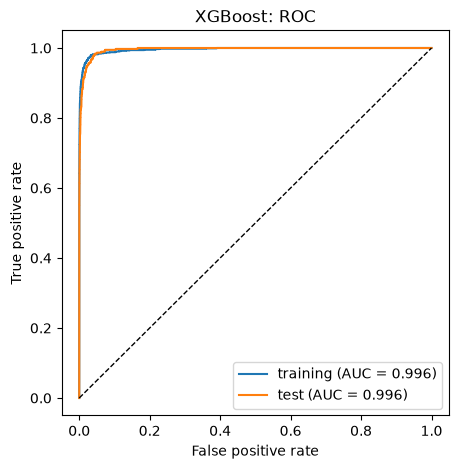

5-fold CV error = 0.0069   test error = 0.0087


In [10]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)


def make_xgb(alpha):
    return XGBClassifier(n_estimators=100, max_depth=3, learning_rate=0.1, reg_alpha=alpha,
                         tree_method="hist", eval_metric="logloss", random_state=SEED, n_jobs=-1)


def cv_errors(X, y, smote):
    """5-fold CV misclassification error for every alpha. With smote=True, SMOTE is applied to the
    training part of each fold only; the held-out part always keeps the original data."""
    errors = {a: [] for a in ALPHAS}
    for tr, va in skf.split(X, y):
        X_fit, y_fit = X[tr], y[tr]
        if smote:
            X_fit, y_fit = SMOTE(random_state=SEED).fit_resample(X_fit, y_fit)
        for a in ALPHAS:
            model = make_xgb(a).fit(X_fit, y_fit)
            errors[a].append(1 - accuracy_score(y[va], model.predict(X[va])))
    return {a: float(np.mean(e)) for a, e in errors.items()}


def best_alpha(cv_err):
    return min(cv_err, key=lambda a: (cv_err[a], -a))


cv_err = cv_errors(Xtr, y_train, smote=False)
alpha_star = best_alpha(cv_err)
display(pd.Series(cv_err, name="CV error").rename_axis("alpha").to_frame().round(5))
print(f"Selected alpha = {alpha_star}   5-fold CV error = {cv_err[alpha_star]:.4f}")

xgb = make_xgb(alpha_star).fit(Xtr, y_train)
res_xgb = report(xgb, "XGBoost")
print(f"5-fold CV error = {cv_err[alpha_star]:.4f}   test error = {res_xgb['test']['error']:.4f}")

**Answer:** The 5-fold cross-validation error (0.0069) is slightly lower than the test error (0.0087); the difference of 0.0018 corresponds to about 29 of the 16,000 test instances, so the cross-validation error is a reasonable estimate of the test error.

### 1(f) XGBoost with L1 regularization after SMOTE

SMOTE creates synthetic positive instances by interpolating between a positive instance and one of its nearest positive neighbours, until both classes have the same size.

**Right way vs. wrong way to cross-validate.** *Right way:* SMOTE is applied inside every cross-validation fold, to the training part of the fold only, and the held-out part keeps its original instances; the error is then estimated on real data only. *Wrong way:* applying SMOTE to the whole training set first and cross-validating afterwards. The synthetic points are then built from positive instances that end up in the held-out folds, so the held-out folds contain near-copies of training points and the cross-validation error is optimistic.

SMOTE is applied to the whole training set (60,000 instances) for the final model. The final model is evaluated on the original (not resampled) training set and on the test set. α is selected in the same way as in 1(e).

,CV error
alpha,
0.0,0.02050
0.1,0.02048
1.0,0.02073
10.0,0.02093
100.0,0.02510


Selected alpha = 0.1   5-fold CV error = 0.0205
Training set after SMOTE (negative, positive): (59000, 59000)
XGBoost with SMOTE, training set: misclassification error = 0.0189, AUC = 0.9942


,pred neg,pred pos
true neg,57937,1063
true pos,71,929


XGBoost with SMOTE, test set: misclassification error = 0.0199, AUC = 0.9938


,pred neg,pred pos
true neg,15334,291
true pos,27,348


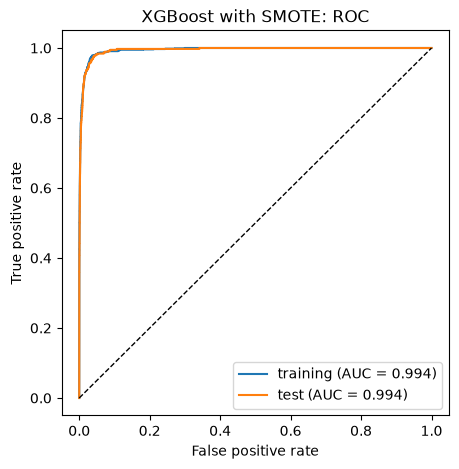

5-fold CV error = 0.0205   test error = 0.0199


,alpha,CV error,training error,test error,training AUC,test AUC
1(e) no compensation,1.0,0.0069,0.0048,0.0087,0.9957,0.9955
1(f) SMOTE,0.1,0.0205,0.0189,0.0199,0.9942,0.9938


In [11]:
cv_err_sm = cv_errors(Xtr, y_train, smote=True)
alpha_sm = best_alpha(cv_err_sm)
display(pd.Series(cv_err_sm, name="CV error").rename_axis("alpha").to_frame().round(5))
print(f"Selected alpha = {alpha_sm}   5-fold CV error = {cv_err_sm[alpha_sm]:.4f}")

X_sm, y_sm = SMOTE(random_state=SEED).fit_resample(Xtr, y_train)
print("Training set after SMOTE (negative, positive):", tuple(int(c) for c in np.bincount(y_sm)))

xgb_sm = make_xgb(alpha_sm).fit(X_sm, y_sm)
res_xgb_sm = report(xgb_sm, "XGBoost with SMOTE")
print(f"5-fold CV error = {cv_err_sm[alpha_sm]:.4f}   test error = {res_xgb_sm['test']['error']:.4f}")

pd.DataFrame({
    "alpha": [alpha_star, alpha_sm],
    "CV error": [cv_err[alpha_star], cv_err_sm[alpha_sm]],
    "training error": [res_xgb["training"]["error"], res_xgb_sm["training"]["error"]],
    "test error": [res_xgb["test"]["error"], res_xgb_sm["test"]["error"]],
    "training AUC": [res_xgb["training"]["auc"], res_xgb_sm["training"]["auc"]],
    "test AUC": [res_xgb["test"]["auc"], res_xgb_sm["test"]["auc"]],
}, index=["1(e) no compensation", "1(f) SMOTE"]).round(4)

**Answer:** SMOTE increases the test error (0.0199 against 0.0087) because the number of false positives grows from 22 to 291, but it reduces the missed positive instances from 117 to 27, so the share of detected positives rises from 68.8% to 92.8% (348 of 375 against 258 of 375). The test AUC is nearly unchanged (0.9938 against 0.9955). The cross-validation error with SMOTE applied inside the folds (0.0205) is close to the test error (0.0199).

## Problem 2 – ISLR 6.6.3

The lasso is fitted by minimizing the RSS subject to Σ|β_j| ≤ s.

**(a)** iv. **Steadily decrease.** Increasing s relaxes the constraint, so the model becomes more flexible and fits the training data better; the training RSS decreases until it reaches the least squares RSS.

**(b)** ii. **Decrease initially, and then eventually start increasing in a U shape.** At first the added flexibility reduces the bias and the test RSS drops; for larger s the model starts to overfit and the test RSS increases again.

**(c)** iii. **Steadily increase.** The variance grows as the model becomes more flexible.

**(d)** iv. **Steadily decrease.** The squared bias falls as the model becomes more flexible.

**(e)** v. **Remain constant.** The irreducible error Var(ε) does not depend on the model, and hence not on s.

## Problem 3 – ISLR 6.6.5

Write x_i = x_i1 = x_i2 for i = 1, 2. Then Σ_j β_j x_ij = (β₁ + β₂) x_i, and the intercept is zero.

**(a)** Ridge regression minimizes

(y₁ − (β₁ + β₂) x₁)² + (y₂ − (β₁ + β₂) x₂)² + λ(β₁² + β₂²).

**(b)** The first two terms depend on β₁ and β₂ only through the sum c = β₁ + β₂. For a fixed c, the penalty satisfies β₁² + β₂² = c²/2 + (β₁ − β₂)²/2, which is smallest when β₁ = β₂ = c/2. Since the objective is strictly convex for λ > 0, the solution is unique and satisfies β̂₁ = β̂₂.

**(c)** The lasso minimizes

(y₁ − (β₁ + β₂) x₁)² + (y₂ − (β₁ + β₂) x₂)² + λ(|β₁| + |β₂|).

**(d)** The loss again depends only on c = β₁ + β₂, and |β₁| + |β₂| ≥ |β₁ + β₂| = |c|, with equality exactly when β₁ and β₂ have the same sign (or one of them is zero). Let c* be the value of c that minimizes the loss + λ|c| (it is unique). Then every pair with β₁ + β₂ = c* and β₁β₂ ≥ 0 is a solution: if c* > 0, all (β₁, β₂) with β₁ + β₂ = c* and β₁, β₂ ≥ 0; if c* < 0, all (β₁, β₂) with β₁ + β₂ = c* and β₁, β₂ ≤ 0. Hence the lasso estimates are not unique: there is a whole line segment of solutions, in contrast to ridge regression.

## Problem 4 – ISLR 8.4.5

The ten estimates of P(Class is Red | X) are 0.1, 0.15, 0.2, 0.2, 0.55, 0.6, 0.6, 0.65, 0.7 and 0.75.

- **Majority vote:** 6 of the 10 estimates are above 0.5, so the final classification is **Red**.
- **Average probability:** the mean of the estimates is 4.5 / 10 = 0.45 < 0.5, so the final classification is **Green**.

## Problem 5 – ISLR 9.7.3

**(a), (b), (d), (e), (g), (h)** are sketched below. Left: the observations, the optimal separating hyperplane (solid line), the margin (dashed lines) and the support vectors (circled). Right: a hyperplane that is not optimal (dotted line) and an additional observation that makes the classes non-separable.

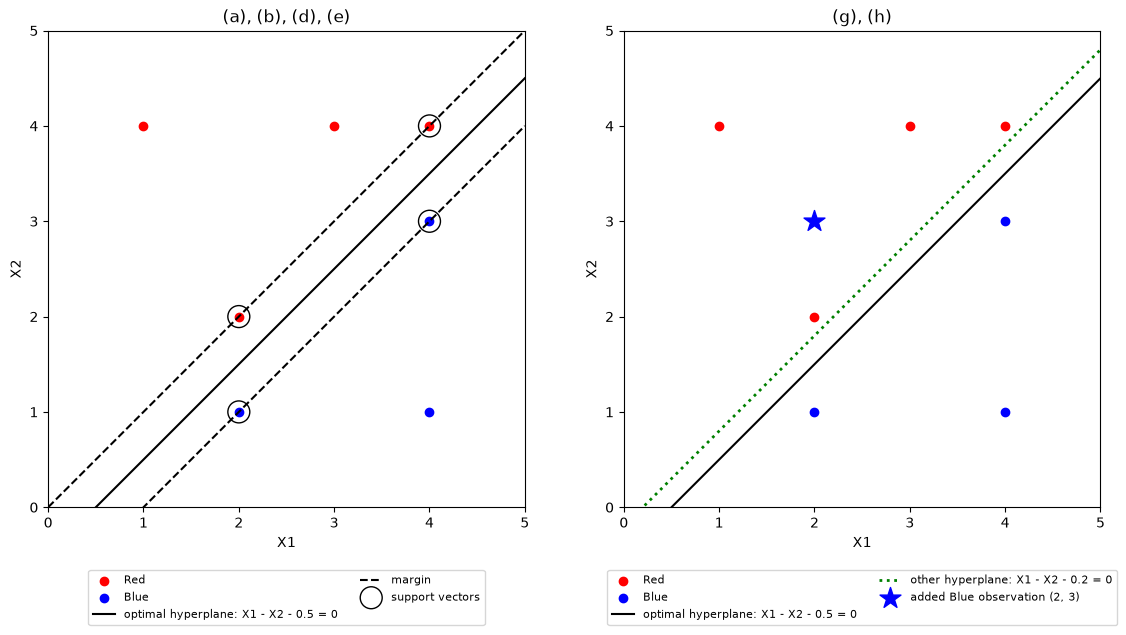

In [12]:
red = np.array([[3, 4], [2, 2], [4, 4], [1, 4]])
blue = np.array([[2, 1], [4, 3], [4, 1]])
support = np.array([[2, 2], [4, 4], [2, 1], [4, 3]])
x = np.linspace(0, 5, 100)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))
for ax in (ax1, ax2):
    ax.scatter(red[:, 0], red[:, 1], c="red", label="Red")
    ax.scatter(blue[:, 0], blue[:, 1], c="blue", label="Blue")
    ax.plot(x, x - 0.5, "k-", label="optimal hyperplane: X1 - X2 - 0.5 = 0")
    ax.set_xlim(0, 5)
    ax.set_ylim(0, 5)
    ax.set_aspect("equal")
    ax.set_xlabel("X1")
    ax.set_ylabel("X2")

ax1.plot(x, x, "k--", label="margin")
ax1.plot(x, x - 1, "k--")
ax1.scatter(support[:, 0], support[:, 1], s=250, facecolors="none", edgecolors="k", label="support vectors")
ax1.set_title("(a), (b), (d), (e)")

ax2.plot(x, x - 0.2, "g:", linewidth=2, label="other hyperplane: X1 - X2 - 0.2 = 0")
ax2.scatter([2], [3], c="blue", marker="*", s=250, label="added Blue observation (2, 3)")
ax2.set_title("(g), (h)")

for ax in (ax1, ax2):
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

**(b)** The optimal separating hyperplane passes midway between the closest points of the two classes, (2, 2), (4, 4) (Red) and (2, 1), (4, 3) (Blue). Its equation is **X₁ − X₂ − 0.5 = 0** (equivalently 0.5 − X₁ + X₂ = 0).

**(c)** Classify to Red if 0.5 − X₁ + X₂ > 0, and classify to Blue otherwise, with β₀ = 0.5, β₁ = −1 and β₂ = 1.

**(d)** The margin is the distance from the hyperplane to the closest observations: |2 − 2 − 0.5| / √2 = 0.5 / √2 = √2 / 4 ≈ 0.354 (dashed lines in the sketch: X₂ = X₁ and X₂ = X₁ − 1).

**(e)** The support vectors are observations 2 (2, 2), 3 (4, 4), 5 (2, 1) and 6 (4, 3).

**(f)** Observation 7 (4, 1) is not a support vector: its distance to the hyperplane is |4 − 1 − 0.5| / √2 ≈ 1.77, much larger than the margin 0.354. A slight movement of this observation (that keeps it outside the margin) does not change the support vectors, and the maximal margin hyperplane depends only on the support vectors, so it does not change.

**(g)** A separating hyperplane that is not optimal is X₁ − X₂ − 0.2 = 0 (0.2 − X₁ + X₂ = 0). It separates the classes, but its margin (0.2 / √2 ≈ 0.14) is smaller than the maximal margin.

**(h)** Adding a Blue observation at (2, 3) (star in the sketch) makes the classes non-separable, since this point lies inside the convex hull of the Red observations.